# 05.11 K-MEANS CLUSTERING - EXERCISES (SOLUTION)

This notebook contains practical exercises on k-means clustering.

## Exercise 1: Basic K-Means Clustering

Use the data generated using `make_blobs`, fit a `KMeans` model with four clusters, and visualize the clusters.

**Important:** K-Means is a **distance-based algorithm** — **always** apply **StandardScaler** or **MinMaxScaler**
before fitting to ensure all features contribute equally to the distance metric.


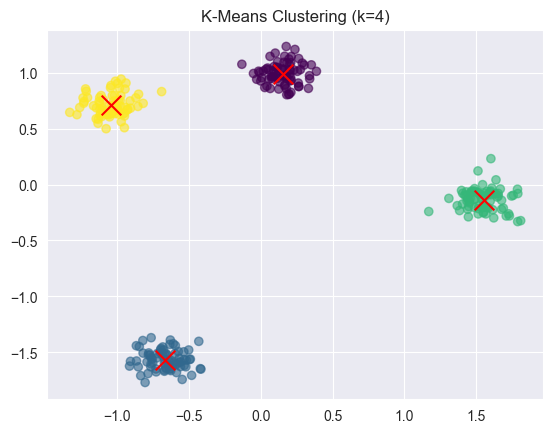

In [2]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Generate data
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.6, random_state=42)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit KMeans
kmeans = KMeans(n_clusters=4, random_state=42)
y_pred = kmeans.fit_predict(X_scaled)

### OR
from sklearn.pipeline import make_pipeline
# Create a pipeline: scale first, then cluster
pipeline = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=4, random_state=42)
)

# Fit and predict in one step
y_pred = pipeline.fit_predict(X)

# Visualize clusters
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_pred, cmap='viridis', alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='x', s=200)
plt.title("K-Means Clustering (k=4)")
plt.show()


## Exercise 2: Predict New Data Points

Use `kmeans.predict()` on new samples and visualize where they fall relative to existing clusters.

Before predicting, make sure new data is **transformed using the same scaler** as used during training.


Predicted cluster indices: [2 2]


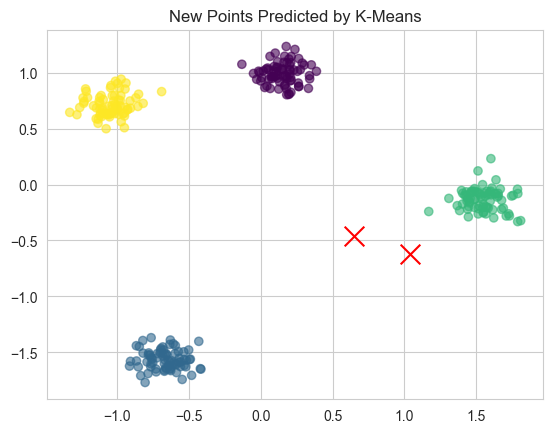

In [14]:
import numpy as np

new_points = np.array([[0, 0], [2, -1]])
new_points_scaled = scaler.transform(new_points)

predictions = kmeans.predict(new_points_scaled)
print("Predicted cluster indices:", predictions)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_pred, cmap='viridis', alpha=0.6)
plt.scatter(new_points_scaled[:, 0], new_points_scaled[:, 1], c='red', s=200, marker='x')
plt.title("New Points Predicted by K-Means")
plt.show()


## (Bonus) Exercise 3: Cluster Evaluation with Silhouette Score

Compute silhouette scores for different cluster counts. Visualize cluster quality.

**Note:** Scaling ensures that the silhouette score reflects **true shape similarity** and not feature magnitude differences.


The silhouette score measures how well each data point fits within its assigned cluster

compared to other clusters. It ranges from -1 to +1:

+1 → well-clustered,  0 → borderline,  -1 → misclassified


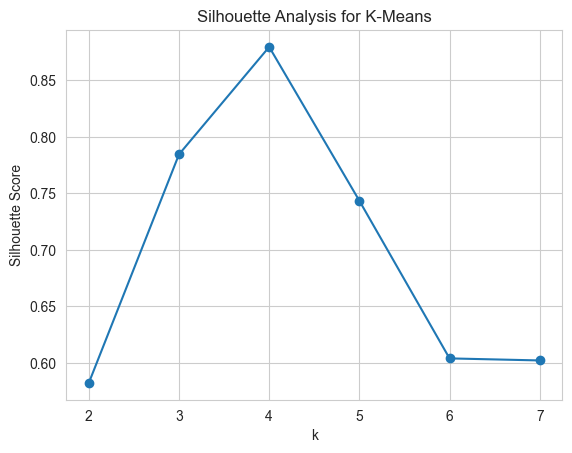

In [15]:
from sklearn.metrics import silhouette_score

scores = []
for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, random_state=42).fit(X_scaled)
    score = silhouette_score(X_scaled, kmeans.labels_)
    ### OR
    #labels = KMeans(n_clusters=k, random_state=42).fit_predict(X_scaled)
    #score = silhouette_score(X_scaled, labels)
    scores.append(score)

plt.plot(range(2, 8), scores, marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis for K-Means')
plt.show()

# Based on the silhoutte analysis, 4 is the optimal number of clusters
